# Editable paper figures — original data paths

This Jupyter notebook reproduces both figures from the original Python script with **editable Matplotlib styles**:

1. **Preservation effects:** condition means (RR, SA, EW) and paired EW − SA effects, confidence intervals, and adjusted *p*-values.
2. **Group preservation:** observations for G1/G2/G3 for SA and EW with group means.

### Data loading

The notebook uses your **real analysis CSV files**, keeping the paths from the original script:

- `analysis/descriptive/arm_summary.csv`
- `analysis/descriptive/baseline_groups.csv`
- `analysis/descriptive/session_metrics.csv`
- `analysis/statistics/reporting/paired_all_views.csv`

These paths are relative to the **replication-package root**. The notebook automatically locates the root by looking in your current working directory and its parent directories. For example, if your `.ipynb` is in the root, next to `analysis/`, it works without edits; it also works when placed in a subdirectory of the project. You can set `PACKAGE_DIR` explicitly in the first code cell if necessary.

**No sample data or fallback:** If the original CSV files are not found, the notebook reports their expected paths rather than plotting fabricated values. The outputs are initially cleared; run the cells locally in your project to display the real figures.

### Editing and running

- **Run → Run All Cells** to read your data and show both plots inline.
- Change `STYLE` for font family, font color, axis/legend text, series colors, marker sizes, dimensions, and so on.
- Change `LABELS` for titles and axis/group captions.
- Enable saving in the export cell for PDF, SVG, and PNG output.

Requires `numpy`, `matplotlib`, and Jupyter/IPython.


## 1 · Imports and dataset configuration

In [8]:
from pathlib import Path
from collections import defaultdict
import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

# Point to your replication-package root containing the analysis/ folder.
# Leave as None to find it automatically from the notebook's working directory.
PACKAGE_DIR = None

# Exactly the same data view as the original Python script.
VIEW = "primary69__main"

REQUIRED_CSVS = (
    Path("analysis/descriptive/arm_summary.csv"),
    Path("analysis/statistics/reporting/paired_all_views.csv"),
    Path("analysis/descriptive/baseline_groups.csv"),
    Path("analysis/descriptive/session_metrics.csv"),
)

def resolve_package_dir(explicit_root=None):
    if explicit_root is not None:
        root = Path(explicit_root).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"PACKAGE_DIR is not a directory: {root}")
        return root
    # Jupyter commonly launches in the notebook directory. Look upward so that
    # a notebook beside the original script (two directories below the root)
    # still finds the project's existing analysis/ CSV paths.
    cwd = Path.cwd().resolve()
    for root in (cwd, *cwd.parents):
        if all((root / relative).is_file() for relative in REQUIRED_CSVS):
            return root
    raise FileNotFoundError(
        "Could not locate the replication package. The notebook looked in "
        f"{cwd} and its parent directories for these four files under analysis/:\n"
        + "\n".join(f"  - {relative}" for relative in REQUIRED_CSVS)
        + "\nSet PACKAGE_DIR to your project root (the folder containing analysis/)."
    )

PACKAGE_DIR = resolve_package_dir(PACKAGE_DIR)

STRATA = [
    ("A", "openai", "Task A · GPT", 35),
    ("A", "anthropic", "Task A · Claude", 35),
    ("B", "openai", "Task B · GPT", 34),
    ("B", "anthropic", "Task B · Claude", 34),
]
GROUPS = ("G1", "G2", "G3")
print("Replication package:", PACKAGE_DIR)


Replication package: /Users/elmiraonagh/Desktop/Research/Reza_project/llm-requirement-revision


## 2 · Edit figure appearance here

In [9]:
# Change these values and rerun the plotting cells below.
STYLE = {
    # Dimensions in INCHES: original IEEE conference text width is 7.14 inches
    "figure_width": 7.14,
    "effects_height": 2.59,
    "groups_height": 3.55,
    "display_dpi": 145,
    "export_dpi": 300,

    # Typography
    "font_family": "DejaVu Sans",  # try "Arial", "Liberation Sans", "Times New Roman"
    "font_size": 8.1,
    "title_size": 8.7,
    "axis_label_size": 8.1,
    "tick_label_size": 7.7,
    "annotation_size": 7.5,
    "legend_size": 7.7,
    "title_weight": "bold",       # "normal" or "bold"

    # Text and canvas colors
    "text_color": "#222222",
    "title_color": "#222222",
    "axis_label_color": "#222222",
    "tick_color": "#3A3A3A",
    "value_label_color": "match_series",   # or e.g. "#222222" for all numeric labels
    "figure_background": "#FFFFFF",
    "axes_background": "#FFFFFF",
    "axis_line_color": "#777777",
    "grid_color": "#BFC4C9",
    "grid_alpha": 0.53,
    "zero_line_color": "#54585D",

    # Colors and symbols for the three experimental conditions
    "series_colors": {"RR": "#777777", "SA": "#D55E00", "EW": "#0072B2"},
    "series_markers": {"RR": "s", "SA": "^", "EW": "o"},
    "point_size": 20,
    "group_point_size": 11,
    "group_mean_size": 27,
    "group_point_alpha": 0.83,
    "error_bar_width": 1.15,

}

# Change plot words independently of the styles above.
LABELS = {
    "mean_panel_title": "(a) Mean loss of prior core-test passes",
    "paired_panel_title": "(b) Paired difference",
    "loss_axis": "Prior core-test passes lost (%)",
    "difference_axis": "EW − SA (percentage points)",
    "adjusted_p": "Adjusted $p$",
    "group_caption": "G1 Unstructured   ·   G2 Structured   ·   G3 Constraint-complete",
    "group_mean": "Group mean",
}

print("Style settings ready. Try changing STYLE['text_color'] or STYLE['series_colors'].")

Style settings ready. Try changing STYLE['text_color'] or STYLE['series_colors'].


## 3 · Load your experimental results from the existing CSV paths


In [10]:
def read_csv(path):
    with Path(path).open(newline="", encoding="utf-8-sig") as stream:
        return list(csv.DictReader(stream))


def load_raw_replication_package(package):
    """Load real data using exactly the four paths in the original script."""
    results = Path(package) / "analysis"
    means = [dict(r, record="condition_mean")
             for r in read_csv(results / "descriptive/arm_summary.csv")
             if r["view"] == VIEW]
    effects = [dict(r, record="paired_effect")
               for r in read_csv(results / "statistics/reporting/paired_all_views.csv")
               if r["view"] == VIEW and r["metric"] == "core_loss_rate"
               and r["contrast"] == "EW minus SA"]
    baseline = {(r["task"], r["group"]): r
                for r in read_csv(results / "descriptive/baseline_groups.csv")
                if r["view"] == VIEW}
    groups = defaultdict(list)
    for row in read_csv(results / "descriptive/session_metrics.csv"):
        if row["view"] == VIEW and row["condition"] in ("SA", "EW"):
            groups[row["task"], row["provider"], row["group"], row["condition"]].append(row)
    points = []
    for (task, provider, group, condition), rows in groups.items():
        for row in sorted(rows, key=lambda item: item["participant_id"]):
            points.append(dict(
                task=task, provider=provider, group=group, condition=condition,
                participant_id=row["participant_id"], group_n=len(rows),
                core_loss_percent=100 * float(row["core_loss_rate"]),
                baseline_pass_mean=baseline[task, group]["core_baseline_pass_mean"],
            ))
    return {"preservation_effects": means + effects,
            "group_preservation": points}


missing = [PACKAGE_DIR / rel for rel in REQUIRED_CSVS if not (PACKAGE_DIR / rel).is_file()]
if missing:
    raise FileNotFoundError("Required CSV file(s) missing:\n" + "\n".join(map(str, missing)))

observations = load_raw_replication_package(PACKAGE_DIR)
print("Loaded REAL experimental results from:", PACKAGE_DIR / "analysis")
print("Figure 1 records:", len(observations["preservation_effects"]))
print("Figure 2 observations:", len(observations["group_preservation"]))


Loaded REAL experimental results from: /Users/elmiraonagh/Desktop/Research/Reza_project/llm-requirement-revision/analysis
Figure 1 records: 16
Figure 2 observations: 276


## 4 · Shared styling and helper functions

In [11]:
def apply_style():
    """Apply text colors, font sizes and export-friendly font options."""
    mpl.rcParams.update({
        "font.family": STYLE["font_family"],
        "font.size": STYLE["font_size"],
        "text.color": STYLE["text_color"],
        "axes.titlesize": STYLE["title_size"],
        "axes.titlecolor": STYLE["title_color"],
        "axes.labelsize": STYLE["axis_label_size"],
        "axes.labelcolor": STYLE["axis_label_color"],
        "xtick.labelsize": STYLE["tick_label_size"],
        "ytick.labelsize": STYLE["tick_label_size"],
        "xtick.color": STYLE["tick_color"],
        "ytick.color": STYLE["tick_color"],
        "axes.edgecolor": STYLE["axis_line_color"],
        "axes.facecolor": STYLE["axes_background"],
        "figure.facecolor": STYLE["figure_background"],
        "savefig.facecolor": STYLE["figure_background"],
        "figure.dpi": STYLE["display_dpi"],
        "pdf.fonttype": 42,        # embed TrueType in PDF
        "svg.fonttype": "none",    # keep SVG lettering editable
        "axes.linewidth": .6,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })


def arm_color(arm):
    return STYLE["series_colors"][arm]


def value_color(arm):
    c = STYLE["value_label_color"]
    return arm_color(arm) if c == "match_series" else c


def clean(ax):
    ax.set_axisbelow(True)
    ax.grid(axis="x", color=STYLE["grid_color"], alpha=STYLE["grid_alpha"], linewidth=.48)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, colors=STYLE["tick_color"])
    ax.tick_params(axis="x", length=2.8, colors=STYLE["tick_color"])


def legend_handles(arms):
    return [Line2D([], [], linestyle="", color=arm_color(arm),
                   marker=STYLE["series_markers"][arm], label=arm, markersize=4.6)
            for arm in arms]


def pformat(value):
    number = float(value)
    if number == 0:
        return "0"
    exponent = int(np.floor(np.log10(abs(number))))
    mantissa = number / 10**exponent
    return rf"${mantissa:.2f}\times 10^{{{exponent}}}$"


apply_style()


## 5 · Figure 1: preservation effects

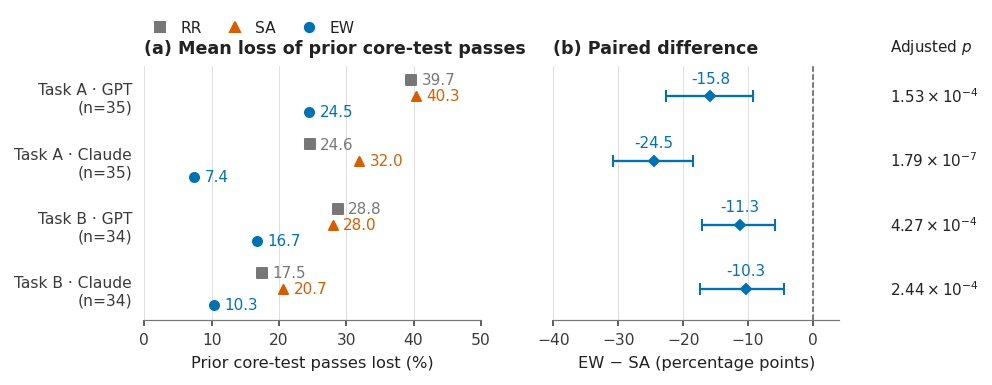

In [62]:
def draw_preservation(rows):
    means, pairs = {}, {}
    for row in rows:
        stratum = (row["task"], row["provider"])
        if row["record"] == "condition_mean":
            means[(*stratum, row["condition"])] = row
        elif row["record"] == "paired_effect":
            pairs[stratum] = row
        else:
            raise ValueError(f"Unexpected record type: {row['record']!r}")
    assert len(rows) == 16 and len(means) == 12 and len(pairs) == 4, "Check Figure 1 input data"

    fig = plt.figure(figsize=(STYLE["figure_width"], STYLE["effects_height"]))
    left = fig.add_axes([.155, .165, .325, .677])
    right = fig.add_axes([.550, .165, .276, .677])
    positions = (3, 2, 1, 0)

    for y, (task, provider, _label, n) in zip(positions, STRATA):
        for arm, offset in (("RR", .25), ("SA", 0), ("EW", -.25)):
            row = means[task, provider, arm]
            assert int(row["programs"]) == n
            x = 100 * float(row["core_loss_rate_mean"])
            left.scatter(x, y + offset, color=arm_color(arm),
                         marker=STYLE["series_markers"][arm],
                         s=STYLE["point_size"], zorder=3)
            left.annotate(f"{x:.1f}", (x, y + offset), xytext=(5, 0),
                          textcoords="offset points", ha="left", va="center",
                          color=value_color(arm), fontsize=STYLE["annotation_size"])

        row = pairs[task, provider]
        assert int(row["n_pairs"]) == n
        effect = float(row["difference_percentage_points"])
        low, high = float(row["ci_low_pp"]), float(row["ci_high_pp"])
        right.errorbar(effect, y, xerr=[[effect-low], [high-effect]], fmt="D",
                       color=arm_color("EW"), markersize=3.7,
                       elinewidth=STYLE["error_bar_width"], capsize=2.8, zorder=3)
        right.annotate(f"{effect:.1f}", (effect, y), xytext=(0, 5),
                       textcoords="offset points", ha="center", va="bottom",
                       color=value_color("EW"), fontsize=STYLE["annotation_size"])
        right.text(1.177, y, pformat(row["exact_holm_p"]),
                   transform=right.get_yaxis_transform(), ha="left", va="center",
                   fontsize=STYLE["annotation_size"], color=STYLE["text_color"])

    left.set_yticks(positions, [f"{label}\n(n={n})" for _, _, label, n in STRATA])
    left.tick_params(axis="y", pad=6)
    left.set(xlim=(0, 50), xticks=range(0, 51, 10), xlabel=LABELS["loss_axis"])
    right.set(yticks=positions, yticklabels=[], xlim=(-40, 4),
              xticks=range(-40, 1, 10), xlabel=LABELS["difference_axis"])
    right.axvline(0, color=STYLE["zero_line_color"], linestyle="--", linewidth=.75)
    for axis in (left, right):
        axis.set_ylim(-.48, 3.48)
        clean(axis)
    left.set_title(LABELS["mean_panel_title"], loc="left", pad=6,
                   weight=STYLE["title_weight"])
    right.set_title(LABELS["paired_panel_title"], loc="left", pad=6,
                    weight=STYLE["title_weight"])
    right.text(1.177, 1.037, LABELS["adjusted_p"], transform=right.transAxes,
               ha="left", va="bottom", fontsize=STYLE["annotation_size"],
               color=STYLE["text_color"])
    fig.legend(handles=legend_handles(("RR", "SA", "EW")), loc="upper left",
               bbox_to_anchor=(.142, 1), ncol=3, frameon=False,
               columnspacing=1.1, handletextpad=.32,
               fontsize=STYLE["legend_size"], labelcolor=STYLE["text_color"])
    return fig

apply_style()
fig_effects = draw_preservation(observations["preservation_effects"])
display(fig_effects)
plt.close(fig_effects)

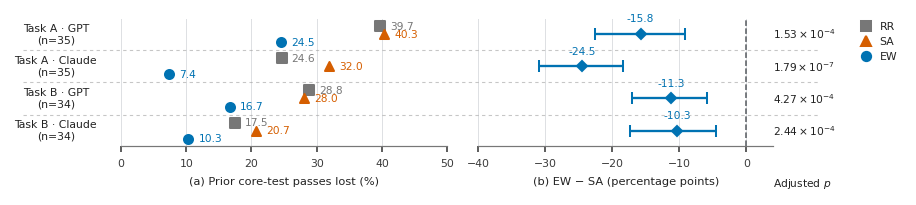

In [75]:

def draw_preservation(rows):
    means, pairs = {}, {}

    for row in rows:
        stratum = (row["task"], row["provider"])
        if row["record"] == "condition_mean":
            means[(*stratum, row["condition"])] = row
        elif row["record"] == "paired_effect":
            pairs[stratum] = row
        else:
            raise ValueError(
                f"Unexpected record type: {row['record']!r}"
            )

    assert (
        len(rows) == 16
        and len(means) == 12
        and len(pairs) == 4
    ), "Check Figure 1 input data"

    # ============================================
    # SIZE AND FONT SETTINGS
    # ============================================

    WIDTH_SCALE = 1   # 12% narrower
    HEIGHT_SCALE = 0.5   # 15% shorter
    FONT_SCALE = 0.70     # 10% smaller fonts

    ANNOTATION_FONT = STYLE["annotation_size"] * FONT_SCALE
    LEGEND_FONT = STYLE["legend_size"] * FONT_SCALE
    AXIS_FONT = plt.rcParams["axes.labelsize"] * FONT_SCALE
    TICK_FONT = plt.rcParams["xtick.labelsize"] * FONT_SCALE
    Y_LABEL_FONT = plt.rcParams["ytick.labelsize"] * FONT_SCALE

    # ============================================
    # LAYOUT SETTINGS
    # ============================================

    # Reduced spacing between graph panels
    LEFT_PANEL = [.175, .165, .315, .677]
    RIGHT_PANEL = [.520, .165, .285, .677]

    # Y-axis label position
    Y_LABEL_X = -0.20

    # P-value column
    P_COLUMN_X = 1.00
    P_LABEL_Y = -0.24

    # Legend position
    LEGEND_X = 0.88
    LEGEND_Y = 0.85

    # ============================================
    # CREATE FIGURE
    # ============================================

    fig = plt.figure(
        figsize=(
            STYLE["figure_width"] * WIDTH_SCALE,
            STYLE["effects_height"] * HEIGHT_SCALE
        )
    )

    left = fig.add_axes(LEFT_PANEL)
    right = fig.add_axes(RIGHT_PANEL)

    positions = (3, 2, 1, 0)

    # ============================================
    # PLOT DATA
    # ============================================

    for y, (task, provider, label, n) in zip(
        positions, STRATA
    ):

        # LEFT PANEL: MEAN CORE LOSS
        for arm, offset in (
            ("RR", .25),
            ("SA", 0),
            ("EW", -.25)
        ):

            row = means[task, provider, arm]
            assert int(row["programs"]) == n

            x = 100 * float(
                row["core_loss_rate_mean"]
            )

            left.scatter(
                x,
                y + offset,
                color=arm_color(arm),
                marker=STYLE["series_markers"][arm],
                s=STYLE["point_size"],
                zorder=3
            )

            left.annotate(
                f"{x:.1f}",
                (x, y + offset),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                color=value_color(arm),
                fontsize=ANNOTATION_FONT
            )

        # RIGHT PANEL: PAIRED DIFFERENCE
        row = pairs[task, provider]
        assert int(row["n_pairs"]) == n

        effect = float(
            row["difference_percentage_points"]
        )

        low = float(row["ci_low_pp"])
        high = float(row["ci_high_pp"])

        right.errorbar(
            effect,
            y,
            xerr=[
                [effect - low],
                [high - effect]
            ],
            fmt="D",
            color=arm_color("EW"),
            markersize=3.7,
            elinewidth=STYLE["error_bar_width"],
            capsize=2.8,
            zorder=3
        )

        right.annotate(
            f"{effect:.1f}",
            (effect, y),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=value_color("EW"),
            fontsize=ANNOTATION_FONT
        )

        # ADJUSTED P-VALUES
        right.text(
            P_COLUMN_X,
            y,
            pformat(row["exact_holm_p"]),
            transform=right.get_yaxis_transform(),
            ha="left",
            va="center",
            fontsize=ANNOTATION_FONT,
            color=STYLE["text_color"],
            clip_on=False
        )

    # ============================================
    # Y-AXIS LABELS
    # ============================================

    left.set_yticks(positions)
    left.set_yticklabels([])
    left.tick_params(axis="y", length=0)

    for y, (_task, _provider, label, n) in zip(
        positions, STRATA
    ):

        left.text(
            Y_LABEL_X,
            y,
            f"{label}\n(n={n})",
            transform=left.get_yaxis_transform(),
            ha="center",
            va="center",
            multialignment="center",
            fontsize=Y_LABEL_FONT,
            color=STYLE["text_color"],
            clip_on=False
        )

    # ============================================
    # X-AXES
    # ============================================

    left.set(
        xlim=(0, 50),
        xticks=range(0, 51, 10),
        xlabel=f"(a) {LABELS['loss_axis']}"
    )

    right.set(
        yticks=positions,
        yticklabels=[],
        xlim=(-40, 4),
        xticks=range(-40, 1, 10),
        xlabel=f"(b) {LABELS['difference_axis']}"
    )

    # ============================================
    # ZERO LINE
    # ============================================

    right.axvline(
        0,
        color=STYLE["zero_line_color"],
        linestyle="--",
        linewidth=.75
    )

    # ============================================
    # CLEAN AXES AND SCALE FONTS
    # ============================================

    for axis in (left, right):
        axis.set_ylim(-.48, 3.48)
        clean(axis)

        axis.xaxis.label.set_fontsize(AXIS_FONT)
        axis.tick_params(
            axis="x",
            labelsize=TICK_FONT
        )

    # ============================================
    # ADJUSTED P HEADING
    # ============================================

    right.text(
        P_COLUMN_X,
        P_LABEL_Y,
        LABELS["adjusted_p"],
        transform=right.transAxes,
        ha="left",
        va="top",
        fontsize=ANNOTATION_FONT,
        color=STYLE["text_color"],
        clip_on=False
    )

    # ============================================
    # CENTERED LEGEND
    # ============================================

    fig.legend(
        handles=legend_handles(("RR", "SA", "EW")),
        loc="upper left",
        bbox_to_anchor=(LEGEND_X, LEGEND_Y),
        ncol=1,                    # Stack vertically
        frameon=False,
        labelspacing=0.45,        # Vertical spacing
        handletextpad=0.25,
        borderaxespad=0,
        fontsize=LEGEND_FONT,
        labelcolor=STYLE["text_color"]
    )


    # ============================================
    # HORIZONTAL DASHED SEPARATORS
    # ============================================

    from matplotlib.lines import Line2D

    SEPARATOR_COLOR = "#A0A0A0"
    SEPARATOR_WIDTH = 0.55
    SEPARATOR_ALPHA = 0.6

    # Horizontal extent across the full diagram
    SEPARATOR_X_START = 0.08
    SEPARATOR_X_END = 0.85

    # Three boundaries between four task-model groups
    for y in (2.5, 1.5, 0.5):

        # Convert data y-coordinate to figure coordinates
        fig_y = (
            LEFT_PANEL[1]
            + LEFT_PANEL[3]
            * ((y + 0.48) / 3.96)
        )

        fig.add_artist(
            Line2D(
                [SEPARATOR_X_START, SEPARATOR_X_END],
                [fig_y, fig_y],
                transform=fig.transFigure,
                color=SEPARATOR_COLOR,
                linewidth=SEPARATOR_WIDTH,
                linestyle=(0, (3, 3)),
                alpha=SEPARATOR_ALPHA,
                zorder=5,
                clip_on=False
            )
        )


    return fig


# ================================================
# DISPLAY FIGURE
# ================================================

apply_style()

fig_effects = draw_preservation(
    observations["preservation_effects"]
)

display(fig_effects)
# Save in the notebook's working directory
OUTPUT_DIR = Path.cwd()

for extension in ("pdf", "svg", "png"):
    output_path = OUTPUT_DIR / f"preservation_effects_v2.{extension}"

    fig_effects.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.03
    )


plt.close(fig_effects)


## 6 · Figure 2: preservation by group

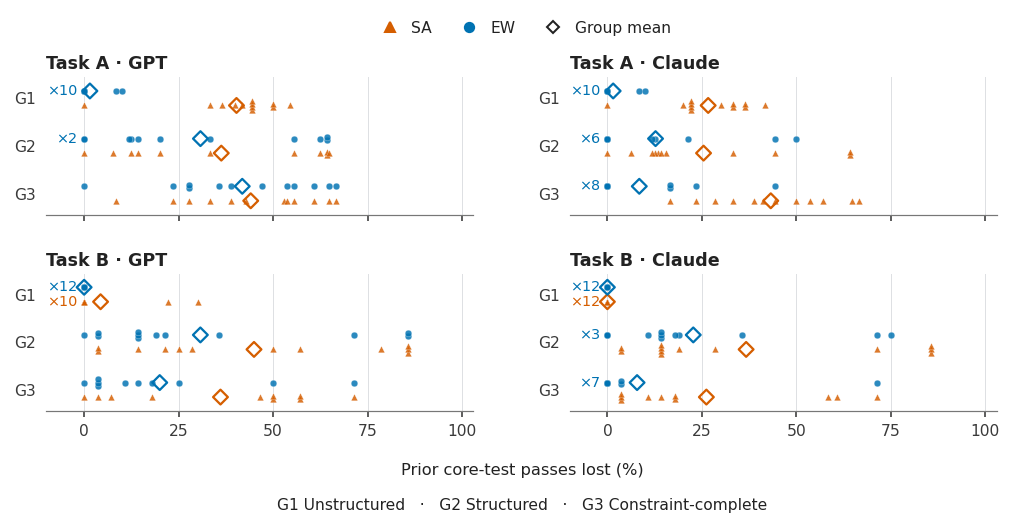

In [ ]:
def offsets(values, step=.065):
    """Spread identical nonzero observations vertically (never change x-values)."""
    by_value = defaultdict(list)
    result = np.zeros(len(values))
    for i, value in enumerate(values):
        if value != 0:
            by_value[round(value, 10)].append(i)
    for indexes in by_value.values():
        for j, i in enumerate(indexes):
            result[i] = (j - (len(indexes) - 1) / 2) * step
    return result


def draw_groups(rows):
    groups = defaultdict(list)
    for row in rows:
        groups[row["task"], row["provider"], row["group"], row["condition"]].append(row)
    assert len(rows) == 276 and len(groups) == 24, "Check Figure 2 input data"

    fig, axes = plt.subplots(2, 2, figsize=(STYLE["figure_width"], STYLE["groups_height"]), sharex=True)
    fig.subplots_adjust(left=.07, right=.988, top=.863, bottom=.215, wspace=.225, hspace=.43)
    for ax, (task, provider, label, n) in zip(axes.flat, STRATA):
        ax.set_title(label, loc="left", weight=STYLE["title_weight"], pad=4)
        for j, group in enumerate(GROUPS):
            for arm, offset in (("SA", -.152), ("EW", .152)):
                members = sorted(groups[task, provider, group, arm], key=lambda r: r["participant_id"])
                values = [float(row["core_loss_percent"]) for row in members]
                assert len(values) == int(members[0]["group_n"])
                zero_n = sum(value == 0 for value in values)
                y = 2 - j + offset
                ax.scatter(values, y + offsets(values), color=arm_color(arm),
                           marker=STYLE["series_markers"][arm],
                           s=STYLE["group_point_size"],
                           edgecolors=STYLE["axes_background"], linewidths=.15,
                           alpha=STYLE["group_point_alpha"], zorder=3)
                if zero_n > 1:
                    ax.annotate(f"×{zero_n}", (0, y), xytext=(-3.4, 0),
                                textcoords="offset points", ha="right", va="center",
                                fontsize=STYLE["annotation_size"]-0.35,
                                color=value_color(arm), zorder=5)
                ax.scatter([np.mean(values)], [y], marker="D",
                           s=STYLE["group_mean_size"], facecolor="none",
                           edgecolor=arm_color(arm), linewidths=1.12, zorder=4)
        ax.set(xlim=(-10, 103), ylim=(-.44, 2.44),
               xticks=range(0, 101, 25), yticks=[2, 1, 0], yticklabels=GROUPS)
        ax.tick_params(axis="y", pad=5)
        clean(ax)
    handles = legend_handles(("SA", "EW"))
    handles.append(Line2D([], [], color=STYLE["text_color"], marker="D",
                          markerfacecolor=STYLE["axes_background"], linestyle="",
                          label=LABELS["group_mean"], markersize=4.5))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.53, 1),
               ncol=3, frameon=False, columnspacing=1.4, handletextpad=.4,
               fontsize=STYLE["legend_size"], labelcolor=STYLE["text_color"])
    fig.text(.53, .099, LABELS["loss_axis"], ha="center", va="center",
             fontsize=STYLE["axis_label_size"], color=STYLE["axis_label_color"])
    fig.text(.53, .032, LABELS["group_caption"], ha="center", va="center",
             fontsize=STYLE["legend_size"], color=STYLE["text_color"])
    return fig

apply_style()
fig_groups = draw_groups(observations["group_preservation"])
display(fig_groups)
plt.close(fig_groups)

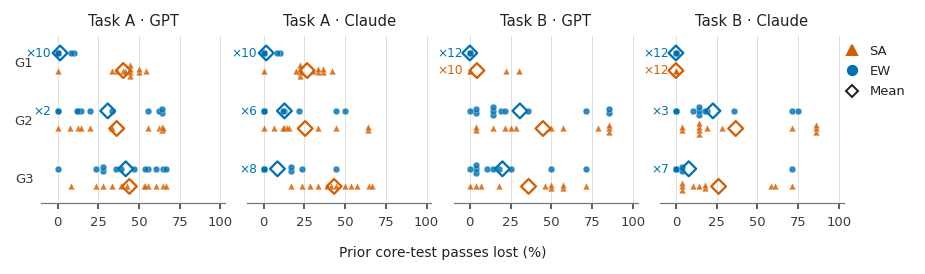

In [85]:

def offsets(values, step=.065):
    """Spread identical nonzero observations vertically without changing x."""
    by_value = defaultdict(list)
    result = np.zeros(len(values))

    for i, value in enumerate(values):
        if value != 0:
            by_value[round(value, 10)].append(i)

    for indexes in by_value.values():
        for j, i in enumerate(indexes):
            result[i] = (
                j - (len(indexes) - 1) / 2
            ) * step

    return result


def draw_groups(rows):
    groups = defaultdict(list)

    for row in rows:
        key = (
            row["task"],
            row["provider"],
            row["group"],
            row["condition"]
        )
        groups[key].append(row)

    assert (
        len(rows) == 276
        and len(groups) == 24
    ), "Check Figure 2 input data"

    # ============================================
    # SIZE AND FONT SETTINGS
    # ============================================

    WIDTH_SCALE = 1.0
    HEIGHT_SCALE = 0.60
    FONT_SCALE = 0.85

    TITLE_FONT = (
        plt.rcParams["axes.titlesize"] * FONT_SCALE
    )
    TICK_FONT = (
        plt.rcParams["xtick.labelsize"] * FONT_SCALE
    )
    ANNOTATION_FONT = (
        STYLE["annotation_size"] * FONT_SCALE
    )
    LEGEND_FONT = (
        STYLE["legend_size"] * FONT_SCALE
    )
    AXIS_FONT = (
        STYLE["axis_label_size"] * FONT_SCALE
    )

    # ============================================
    # LAYOUT SETTINGS
    # ============================================

    # Four plots arranged horizontally
    LEFT_MARGIN = 0.055
    RIGHT_MARGIN = 0.83

    TOP_MARGIN = 0.79
    BOTTOM_MARGIN = 0.25

    PANEL_SPACING = 0.12

    # Right-side vertical legend
    LEGEND_X = 0.82
    LEGEND_Y = 0.78
    LEGEND_SPACING = 0.55

    # Shared x-axis label
    AXIS_LABEL_X = (LEFT_MARGIN + RIGHT_MARGIN) / 2
    AXIS_LABEL_Y = 0.09

    # ============================================
    # CREATE FIGURE
    # ============================================

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            STYLE["figure_width"] * WIDTH_SCALE,
            STYLE["groups_height"] * HEIGHT_SCALE
        ),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=LEFT_MARGIN,
        right=RIGHT_MARGIN,
        top=TOP_MARGIN,
        bottom=BOTTOM_MARGIN,
        wspace=PANEL_SPACING
    )

    # ============================================
    # PLOT TASK–MODEL COMBINATIONS
    # ============================================

    for ax, (task, provider, label, n) in zip(
        axes, STRATA
    ):

        # ----------------------------------------
        # PANEL TITLE — NOT BOLD
        # ----------------------------------------

        ax.set_title(
            label,
            loc="center",
            weight="normal",
            pad=5,
            fontsize=TITLE_FONT
        )

        # ----------------------------------------
        # G1 / G2 / G3 OBSERVATIONS
        # ----------------------------------------

        for j, group in enumerate(GROUPS):

            for arm, offset in (
                ("SA", -.152),
                ("EW", .152)
            ):

                members = sorted(
                    groups[
                        task,
                        provider,
                        group,
                        arm
                    ],
                    key=lambda r: r["participant_id"]
                )

                values = [
                    float(row["core_loss_percent"])
                    for row in members
                ]

                assert len(values) == int(
                    members[0]["group_n"]
                )

                zero_n = sum(
                    value == 0
                    for value in values
                )

                y = 2 - j + offset

                # Individual observations
                ax.scatter(
                    values,
                    y + offsets(values),
                    color=arm_color(arm),
                    marker=STYLE["series_markers"][arm],
                    s=STYLE["group_point_size"],
                    edgecolors=STYLE["axes_background"],
                    linewidths=0.15,
                    alpha=STYLE["group_point_alpha"],
                    zorder=3
                )

                # Number of overlapping zero values
                if zero_n > 1:
                    ax.annotate(
                        f"×{zero_n}",
                        (0, y),
                        xytext=(-3.4, 0),
                        textcoords="offset points",
                        ha="right",
                        va="center",
                        fontsize=ANNOTATION_FONT - 0.35,
                        color=value_color(arm),
                        zorder=5
                    )

                # Group mean: hollow diamond
                ax.scatter(
                    [np.mean(values)],
                    [y],
                    marker="D",
                    s=STYLE["group_mean_size"],
                    facecolor="none",
                    edgecolor=arm_color(arm),
                    linewidths=1.12,
                    zorder=4
                )

        # ========================================
        # AXIS FORMATTING
        # ========================================

        ax.set(
            xlim=(-10, 103),
            ylim=(-.44, 2.44),
            xticks=range(0, 101, 25),
            yticks=[2, 1, 0]
        )

        ax.tick_params(
            axis="x",
            labelsize=TICK_FONT
        )

        ax.tick_params(
            axis="y",
            labelsize=TICK_FONT,
            pad=4
        )

        clean(ax)

    # ============================================
    # Y-AXIS LABELS
    # ============================================

    # Display G1, G2, G3 only on the first panel
    axes[0].set_yticklabels(GROUPS)

    for ax in axes[1:]:
        ax.tick_params(
            axis="y",
            labelleft=False
        )

    # ============================================
    # RIGHT-SIDE VERTICAL LEGEND
    # ============================================

    handles = legend_handles(("SA", "EW"))

    handles.append(
        Line2D(
            [], [],
            color=STYLE["text_color"],
            marker="D",
            markerfacecolor=STYLE["axes_background"],
            linestyle="",
            label="Mean",
            markersize=4.5
        )
    )

    fig.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(
            LEGEND_X,
            LEGEND_Y
        ),
        ncol=1,
        frameon=False,
        labelspacing=LEGEND_SPACING,
        handletextpad=0.35,
        borderaxespad=0,
        fontsize=LEGEND_FONT,
        labelcolor=STYLE["text_color"]
    )

    # ============================================
    # SHARED X-AXIS LABEL
    # ============================================

    fig.text(
        AXIS_LABEL_X,
        AXIS_LABEL_Y,
        LABELS["loss_axis"],
        ha="center",
        va="center",
        fontsize=AXIS_FONT,
        color=STYLE["axis_label_color"]
    )

    return fig


# ================================================
# DISPLAY AND EXPORT
# ================================================

from pathlib import Path

apply_style()

fig_groups = draw_groups(
    observations["group_preservation"]
)

# Display inside Jupyter notebook
display(fig_groups)

# Save in notebook's working directory
OUTPUT_DIR = Path.cwd()

for extension in ("pdf", "svg", "png"):

    output_path = (
        OUTPUT_DIR / f"group_preservation_v2.{extension}"
    )

    fig_groups.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.03
    )

    # print(f"Saved: {output_path}")

plt.close(fig_groups)


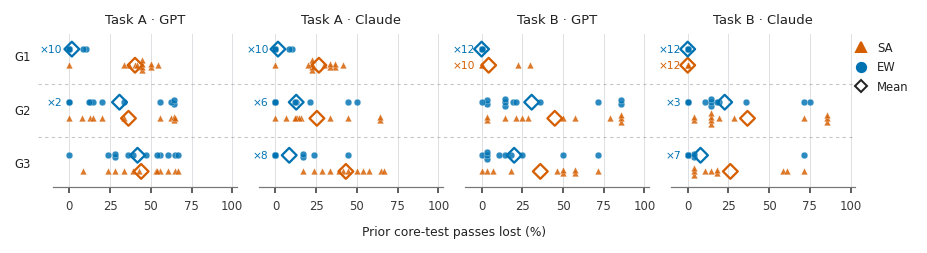

In [101]:

from collections import defaultdict
from matplotlib.lines import Line2D
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def offsets(values, step=.065):
    """Spread identical nonzero observations vertically without changing x."""
    by_value = defaultdict(list)
    result = np.zeros(len(values))

    for i, value in enumerate(values):
        if value != 0:
            by_value[round(value, 10)].append(i)

    for indexes in by_value.values():
        for j, i in enumerate(indexes):
            result[i] = (
                j - (len(indexes) - 1) / 2
            ) * step

    return result


def draw_groups(rows):
    groups = defaultdict(list)

    for row in rows:
        key = (
            row["task"],
            row["provider"],
            row["group"],
            row["condition"]
        )
        groups[key].append(row)

    assert (
        len(rows) == 276
        and len(groups) == 24
    ), "Check Figure 2 input data"

    # ============================================
    # SIZE AND FONT SETTINGS
    # ============================================

    WIDTH_SCALE = 1.0
    HEIGHT_SCALE = 0.55
    FONT_SCALE = 0.75

    TITLE_FONT = (
        plt.rcParams["axes.titlesize"] * FONT_SCALE
    )
    TICK_FONT = (
        plt.rcParams["xtick.labelsize"] * FONT_SCALE
    )
    ANNOTATION_FONT = (
        STYLE["annotation_size"] * FONT_SCALE
    )
    LEGEND_FONT = (
        STYLE["legend_size"] * FONT_SCALE
    )
    AXIS_FONT = (
        STYLE["axis_label_size"] * FONT_SCALE
    )

    # ============================================
    # LAYOUT SETTINGS
    # ============================================

    LEFT_MARGIN = 0.055
    RIGHT_MARGIN = 0.83
    TOP_MARGIN = 0.79
    BOTTOM_MARGIN = 0.25
    PANEL_SPACING = 0.12

    # Right-side vertical legend
    LEGEND_X = 0.82
    LEGEND_Y = 0.78
    LEGEND_SPACING = 0.55

    # Shared x-axis label
    AXIS_LABEL_X = (LEFT_MARGIN + RIGHT_MARGIN) / 2
    AXIS_LABEL_Y = 0.09

    # ============================================
    # DASHED SEPARATOR SETTINGS
    # ============================================

    SEPARATOR_COLOR = "#A0A0A0"
    SEPARATOR_WIDTH = 0.55
    SEPARATOR_ALPHA = 0.60

    # Lines extend from y-axis labels to the
    # right edge of the fourth panel
    SEPARATOR_X_START = 0.04
    SEPARATOR_X_END = 0.83

    # ============================================
    # CREATE FIGURE
    # ============================================

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            STYLE["figure_width"] * WIDTH_SCALE,
            STYLE["groups_height"] * HEIGHT_SCALE
        ),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=LEFT_MARGIN,
        right=RIGHT_MARGIN,
        top=TOP_MARGIN,
        bottom=BOTTOM_MARGIN,
        wspace=PANEL_SPACING
    )

    # ============================================
    # PLOT TASK–MODEL COMBINATIONS
    # ============================================

    for ax, (task, provider, label, n) in zip(
        axes, STRATA
    ):

        # ----------------------------------------
        # PANEL TITLE — REGULAR WEIGHT
        # ----------------------------------------

        ax.set_title(
            label,
            loc="center",
            weight="normal",
            pad=5,
            fontsize=TITLE_FONT
        )

        # ----------------------------------------
        # G1 / G2 / G3 OBSERVATIONS
        # ----------------------------------------

        for j, group in enumerate(GROUPS):

            for arm, offset in (
                ("SA", -.152),
                ("EW", .152)
            ):

                members = sorted(
                    groups[
                        task,
                        provider,
                        group,
                        arm
                    ],
                    key=lambda r: r["participant_id"]
                )

                values = [
                    float(row["core_loss_percent"])
                    for row in members
                ]

                assert len(values) == int(
                    members[0]["group_n"]
                )

                zero_n = sum(
                    value == 0
                    for value in values
                )

                y = 2 - j + offset

                # Individual observations
                ax.scatter(
                    values,
                    y + offsets(values),
                    color=arm_color(arm),
                    marker=STYLE["series_markers"][arm],
                    s=STYLE["group_point_size"],
                    edgecolors=STYLE["axes_background"],
                    linewidths=0.15,
                    alpha=STYLE["group_point_alpha"],
                    zorder=3
                )

                # Number of overlapping zero values
                if zero_n > 1:
                    ax.annotate(
                        f"×{zero_n}",
                        (0, y),
                        xytext=(-3.4, 0),
                        textcoords="offset points",
                        ha="right",
                        va="center",
                        fontsize=ANNOTATION_FONT - 0.35,
                        color=value_color(arm),
                        zorder=5
                    )

                # Group mean: hollow diamond
                ax.scatter(
                    [np.mean(values)],
                    [y],
                    marker="D",
                    s=STYLE["group_mean_size"],
                    facecolor="none",
                    edgecolor=arm_color(arm),
                    linewidths=1.12,
                    zorder=4
                )

        # ========================================
        # AXIS FORMATTING
        # ========================================

        ax.set(
            xlim=(-10, 103),
            ylim=(-.44, 2.44),
            xticks=range(0, 101, 25),
            yticks=[2, 1, 0]
        )

        ax.tick_params(
            axis="x",
            labelsize=TICK_FONT
        )

        ax.tick_params(
            axis="y",
            labelsize=TICK_FONT,
            pad=4
        )

        clean(ax)

    # ============================================
    # Y-AXIS LABELS
    # ============================================

    # G1, G2, G3 only on the first panel
    # ============================================
    # Y-AXIS LABELS — CUSTOM POSITION
    # ============================================

    Y_LABEL_X = -0.12  # More negative = further left

    # Hide automatic y-axis labels
    for ax in axes:
        ax.tick_params(axis="y", labelleft=False)

    # Draw labels manually on the first panel
    for y, group in zip([2, 1, 0], GROUPS):
        axes[0].text(
            Y_LABEL_X,
            y,
            group,
            transform=axes[0].get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=TICK_FONT,
            color=STYLE["text_color"],
            clip_on=False
        )

    # ============================================
    # RIGHT-SIDE VERTICAL LEGEND
    # ============================================

    handles = legend_handles(("SA", "EW"))

    handles.append(
        Line2D(
            [], [],
            color=STYLE["text_color"],
            marker="D",
            markerfacecolor=STYLE["axes_background"],
            linestyle="",
            label="Mean",
            markersize=4.5
        )
    )

    fig.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(
            LEGEND_X,
            LEGEND_Y
        ),
        ncol=1,
        frameon=False,
        labelspacing=LEGEND_SPACING,
        handletextpad=0.35,
        borderaxespad=0,
        fontsize=LEGEND_FONT,
        labelcolor=STYLE["text_color"]
    )

    # ============================================
    # SHARED X-AXIS LABEL
    # ============================================

    fig.text(
        AXIS_LABEL_X,
        AXIS_LABEL_Y,
        LABELS["loss_axis"],
        ha="center",
        va="center",
        fontsize=AXIS_FONT,
        color=STYLE["axis_label_color"]
    )

    # ============================================
    # TWO HORIZONTAL DASHED SEPARATORS
    # ============================================

    # G1 center: y=2
    # G2 center: y=1
    # G3 center: y=0
    #
    # Place lines at y=1.5 and y=0.5.

    for y in (1.5, 0.5):

        # Convert data y-coordinate into figure
        # coordinates so that each separator
        # crosses all four panels continuously.

        fig_y = (
            BOTTOM_MARGIN
            + (TOP_MARGIN - BOTTOM_MARGIN)
            * ((y + 0.44) / 2.88)
        )

        fig.add_artist(
            Line2D(
                [SEPARATOR_X_START, SEPARATOR_X_END],
                [fig_y, fig_y],
                transform=fig.transFigure,
                color=SEPARATOR_COLOR,
                linewidth=SEPARATOR_WIDTH,
                linestyle=(0, (3, 3)),
                alpha=SEPARATOR_ALPHA,
                zorder=5,
                clip_on=False
            )
        )

    return fig


# ================================================
# DISPLAY AND EXPORT
# ================================================

apply_style()

fig_groups = draw_groups(
    observations["group_preservation"]
)

# Display inside Jupyter
display(fig_groups)

# Save in notebook's working directory
OUTPUT_DIR = Path.cwd()

for extension in ("pdf", "svg", "png"):

    output_path = (
        OUTPUT_DIR / f"group_preservation_v3.{extension}"
    )

    fig_groups.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.03
    )

plt.close(fig_groups)


## 7 · Optional: export your edited figures

In [ ]:
# Turn on to write the figures to disk. PDFs/SVGs preserve vector artwork.
SAVE_EXPORTS = False
# Export location from the original script. Change to a new directory if you
# want to keep the previously generated PDFs untouched.
EXPORT_DIR = PACKAGE_DIR / "outputs" / "figures"
EXPORT_FORMATS = ("pdf", "svg", "png")  # remove formats you don't need

if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for stem, draw_fn in (
        ("preservation_effects", draw_preservation),
        ("group_preservation", draw_groups),
    ):
        apply_style()
        figure = draw_fn(observations[stem])
        for ext in EXPORT_FORMATS:
            destination = EXPORT_DIR / f"{stem}.{ext}"
            options = {"dpi": STYLE["export_dpi"], "bbox_inches": "tight", "pad_inches": .08}
            if ext == "pdf":
                options["metadata"] = {"CreationDate": None, "ModDate": None}
            figure.savefig(destination, **options)
            print("Saved:", destination)
        plt.close(figure)
else:
    print("No files exported. Set SAVE_EXPORTS = True to save PDF, SVG and/or PNG figures.")


No files exported. Set SAVE_EXPORTS = True to save PDF, SVG and/or PNG figures.


### Quick edits

- **All lettering color:** `STYLE["text_color"] = "#222222"` (also adjust `title_color`, `axis_label_color`, and `tick_color` if you want them identical).
- **RR, SA, EW colors:** change the three `STYLE["series_colors"]` values.
- **Font family:** set `STYLE["font_family"] = "Liberation Sans"` (or a font installed on your system).
- **Larger labels:** increase `title_size`, `axis_label_size`, `tick_label_size`, and `annotation_size`.
- **Larger panels:** increase `figure_width`, `effects_height`, or `groups_height`.
- **Editable PowerPoint graphics:** export SVG; `svg.fonttype = "none"` keeps text editable in compatible programs.

The plotting logic and data filtering follow the original script. **This notebook never replaces missing data with example values.**
